# Data Analysis: Complex-Simple Sentence Pairs Dataset

This notebook performs comprehensive analysis on the Amsterdam municipal documents dataset containing aligned complex-simple sentence pairs.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)


In [6]:
# Load the dataset
df = pd.read_csv('complex-simple-v1-anonymized.csv')

# Basic information
print(f"Dataset shape: {df.shape}")
print(f"\nColumn names: {df.columns.tolist()}")
print(f"\nFirst few rows:")
df.head(10)

Dataset shape: (1310, 3)

Column names: ['Document ID', 'Complex', 'Simple']

First few rows:


,Document ID,Complex,Simple
0,1,De gemeente en GVB hebben een onderzoek uit laten voeren naar de behoeften en kansen voor nieuwe...,We onderzochten in oktober 2019 de behoeften en kansen voor nieuwe vormen van vervoer.
1,1,"Bijvoorbeeld een deelauto -fiets, of -scooter voor bewoners uit de Eendracht.","Bijvoorbeeld een deelauto, deelfiets, of deelscooter voor bewoners uit de Eendracht."
2,1,Uit het bewonersonderzoek komt naar voren dat er behoefte is aan (openbaar) vervoer dat betrouwb...,Uit het bewonersonderzoek blijkt dat bewoners (openbaar) vervoer willen dat betrouwbaar en relat...
3,1,Ook komt naar voren dat verschillende bewoners niet bekend zijn met huidige vervoersalternatieve...,Of niet weten hoe ze dat kunnen gebruiken.
4,1,"Daarnaast geven de meeste bewoners aan buslijn 21 terug te willen in de buurt, of een betere ver...",Daarnaast willen de meeste bewoners buslijn 21 terug in de buurt. Of een betere verbinding met d...
5,2,Hygiënemaatregelen ten tijde van COVID-19 voor Horecavoorzieningen,Hygiënemaatregelen tijdens COVID-19 voor Horecavoorzieningen
6,3,Hygiënemaatregelen ten tijde van COVID-19 | voor gebedshuizen,Hygiënemaatregelen tijdens COVID-19 voor gebedshuizen
7,4,Hygiënemaatregelen ten tijde van COVID-19 voor vakantieverblijven,Hygiënemaatregelen tijdens COVID-19 voor vakantieverblijven
8,4,Zet een paar keer per dag even (30 minuten) een raam open.,Zet een paar keer per dag 30 minuten een raam open.
9,4,Desinfectie is niet nodig tijdens quarantaine periode.,Desinfectie is niet nodig tijdens de quarantaineperiode.


In [7]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())
print(f"\nData types:")
print(df.dtypes)

Missing values:
Document ID    0
Complex        0
Simple         0
dtype: int64

Data types:
Document ID     int64
Complex        object
Simple         object
dtype: object


## Train/Validation/Test Split (Exact sizes)

> Reproduce the deterministic split used for SFT (Train≈1000, Validation=150, Test=160).

In [8]:
# Deterministische in-memory split: train=1000, valid=150, test=160
SEED = 2024
N_TRAIN, N_VALID, N_TEST = 1000, 150, 160

# Controle dat dataset groot genoeg is
total_needed = N_TRAIN + N_VALID + N_TEST
assert len(df) >= total_needed, f"Dataset te klein ({len(df)} < {total_needed})"

# Stabiele ordering + deterministische shuffle
stable_df = (
    df.assign(__row_id=np.arange(len(df)))
      .sort_values(by=['Document ID', 'Complex', 'Simple'])
      .reset_index(drop=True)
)

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(stable_df))
stable_df = stable_df.iloc[perm].reset_index(drop=True)

# Slices
train_df = stable_df.iloc[:N_TRAIN].drop(columns='__row_id').copy()
valid_df = stable_df.iloc[N_TRAIN:N_TRAIN+N_VALID].drop(columns='__row_id').copy()
test_df  = stable_df.iloc[N_TRAIN+N_VALID:N_TRAIN+N_VALID+N_TEST].drop(columns='__row_id').copy()

# Optioneel: dictionary voor gemak
splits = {'train': train_df, 'valid': valid_df, 'test': test_df}

# Sanity checks
print("Split sizes →", {k: len(v) for k, v in splits.items()})
# Uniekheid-Check
ids_train = set(stable_df['__row_id'].iloc[:N_TRAIN])
ids_valid = set(stable_df['__row_id'].iloc[N_TRAIN:N_TRAIN+N_VALID])
ids_test  = set(stable_df['__row_id'].iloc[N_TRAIN+N_VALID:N_TRAIN+N_VALID+N_TEST])
assert not (ids_train & ids_valid or ids_train & ids_test or ids_valid & ids_test), "Overlap tussen splits"
print("Overlap check → OK (geen overlap)")

df = train_df.copy()
print(f"Analyse draait op TRAIN set -> shape: {df.shape}")

Split sizes → {'train': 1000, 'valid': 150, 'test': 160}
Overlap check → OK (geen overlap)
Analyse draait op TRAIN set -> shape: (1000, 3)


## 2. Document Distribution Analysis

In [9]:
# Analyze document distribution
doc_counts = df['Document ID'].value_counts().sort_index()

print(f"Number of unique documents: {df['Document ID'].nunique()}")
print(f"\nSentence pairs per document:")
print(doc_counts)
print(f"\nStatistics:")
print(f"  Mean pairs per document: {doc_counts.mean():.2f}")
print(f"  Median pairs per document: {doc_counts.median():.2f}")
print(f"  Min pairs per document: {doc_counts.min()}")
print(f"  Max pairs per document: {doc_counts.max()}")

Number of unique documents: 47

Sentence pairs per document:
Document ID
1       3
2       1
4       5
5       9
6      24
7      14
8       2
9       3
10      2
11     13
12     75
13     35
14    159
15     22
16     15
17      7
18     14
19      8
20     16
21     14
22      6
23     13
24      4
25     13
26      2
27     31
28      8
29     18
30      6
31     82
32      6
33     28
34    108
35    117
36      5
37      2
38     30
39     41
40      4
41      7
42      9
43      4
44      1
45      1
46      2
47      6
48      5
Name: count, dtype: int64

Statistics:
  Mean pairs per document: 21.28
  Median pairs per document: 8.00
  Min pairs per document: 1
  Max pairs per document: 159


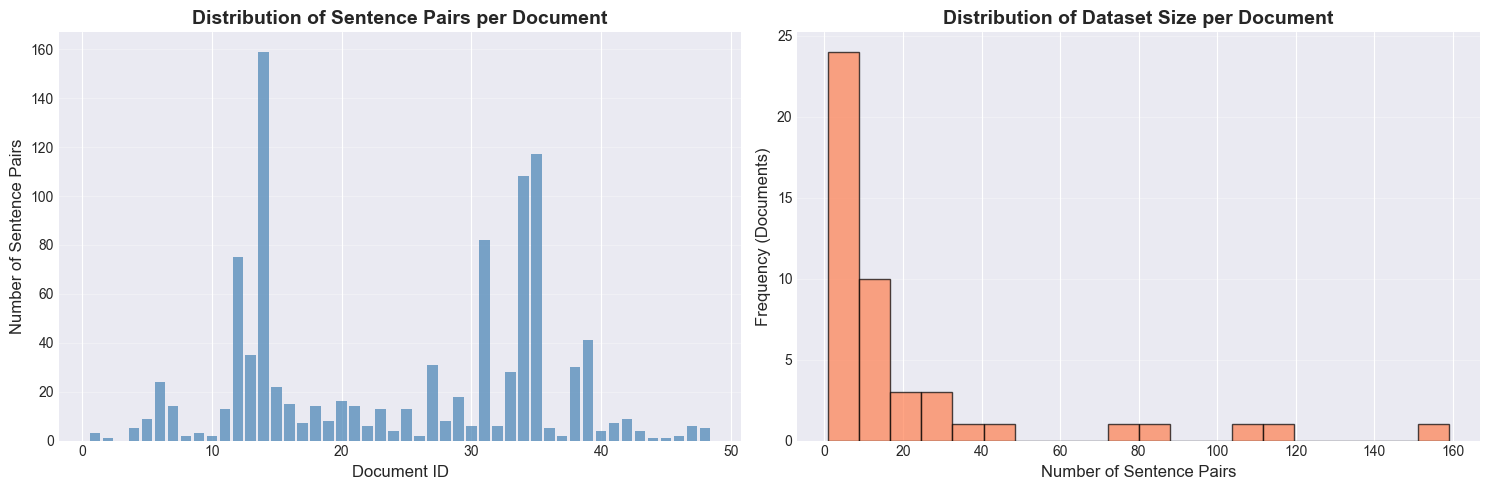

In [10]:
# Visualize document distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar plot
axes[0].bar(doc_counts.index, doc_counts.values, color='steelblue', alpha=0.7)
axes[0].set_xlabel('Document ID', fontsize=12)
axes[0].set_ylabel('Number of Sentence Pairs', fontsize=12)
axes[0].set_title('Distribution of Sentence Pairs per Document', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# Histogram
axes[1].hist(doc_counts.values, bins=20, color='coral', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Number of Sentence Pairs', fontsize=12)
axes[1].set_ylabel('Frequency (Documents)', fontsize=12)
axes[1].set_title('Distribution of Dataset Size per Document', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Text Length Analysis

In [11]:
# Calculate text lengths
df['complex_length'] = df['Complex'].str.len()
df['simple_length'] = df['Simple'].str.len()
df['complex_words'] = df['Complex'].str.split().str.len()
df['simple_words'] = df['Simple'].str.split().str.len()

# Calculate reduction metrics
df['length_reduction'] = df['complex_length'] - df['simple_length']
df['length_reduction_pct'] = ((df['complex_length'] - df['simple_length']) / df['complex_length'] * 100).round(2)
df['word_reduction'] = df['complex_words'] - df['simple_words']
df['word_reduction_pct'] = ((df['complex_words'] - df['simple_words']) / df['complex_words'] * 100).round(2)

print("Character Length Statistics:")
print(f"\nComplex sentences:")
print(df['complex_length'].describe())
print(f"\nSimple sentences:")
print(df['simple_length'].describe())
print(f"\nLength reduction (characters):")
print(df['length_reduction'].describe())

Character Length Statistics:

Complex sentences:
count    1000.000000
mean      103.596000
std        53.052685
min        11.000000
25%        66.000000
50%        94.000000
75%       130.000000
max       427.000000
Name: complex_length, dtype: float64

Simple sentences:
count    1000.000000
mean       93.989000
std        44.419004
min        11.000000
25%        64.000000
50%        86.000000
75%       116.000000
max       380.000000
Name: simple_length, dtype: float64

Length reduction (characters):
count    1000.000000
mean        9.607000
std        30.255412
min      -119.000000
25%        -2.000000
50%         5.000000
75%        14.000000
max       280.000000
Name: length_reduction, dtype: float64


In [12]:
print("Word Count Statistics:")
print(f"\nComplex sentences:")
print(df['complex_words'].describe())
print(f"\nSimple sentences:")
print(df['simple_words'].describe())
print(f"\nWord reduction:")
print(df['word_reduction'].describe())
print(f"\nAverage word reduction: {df['word_reduction'].mean():.2f} words ({df['word_reduction_pct'].mean():.2f}%)")

Word Count Statistics:

Complex sentences:
count    1000.000000
mean       16.091000
std         8.069686
min         3.000000
25%        11.000000
50%        15.000000
75%        20.000000
max        69.000000
Name: complex_words, dtype: float64

Simple sentences:
count    1000.000000
mean       14.783000
std         6.940611
min         3.000000
25%        10.000000
50%        14.000000
75%        18.000000
max        55.000000
Name: simple_words, dtype: float64

Word reduction:
count    1000.000000
mean        1.308000
std         4.727948
min       -20.000000
25%         0.000000
50%         1.000000
75%         2.000000
max        42.000000
Name: word_reduction, dtype: float64

Average word reduction: 1.31 words (2.76%)


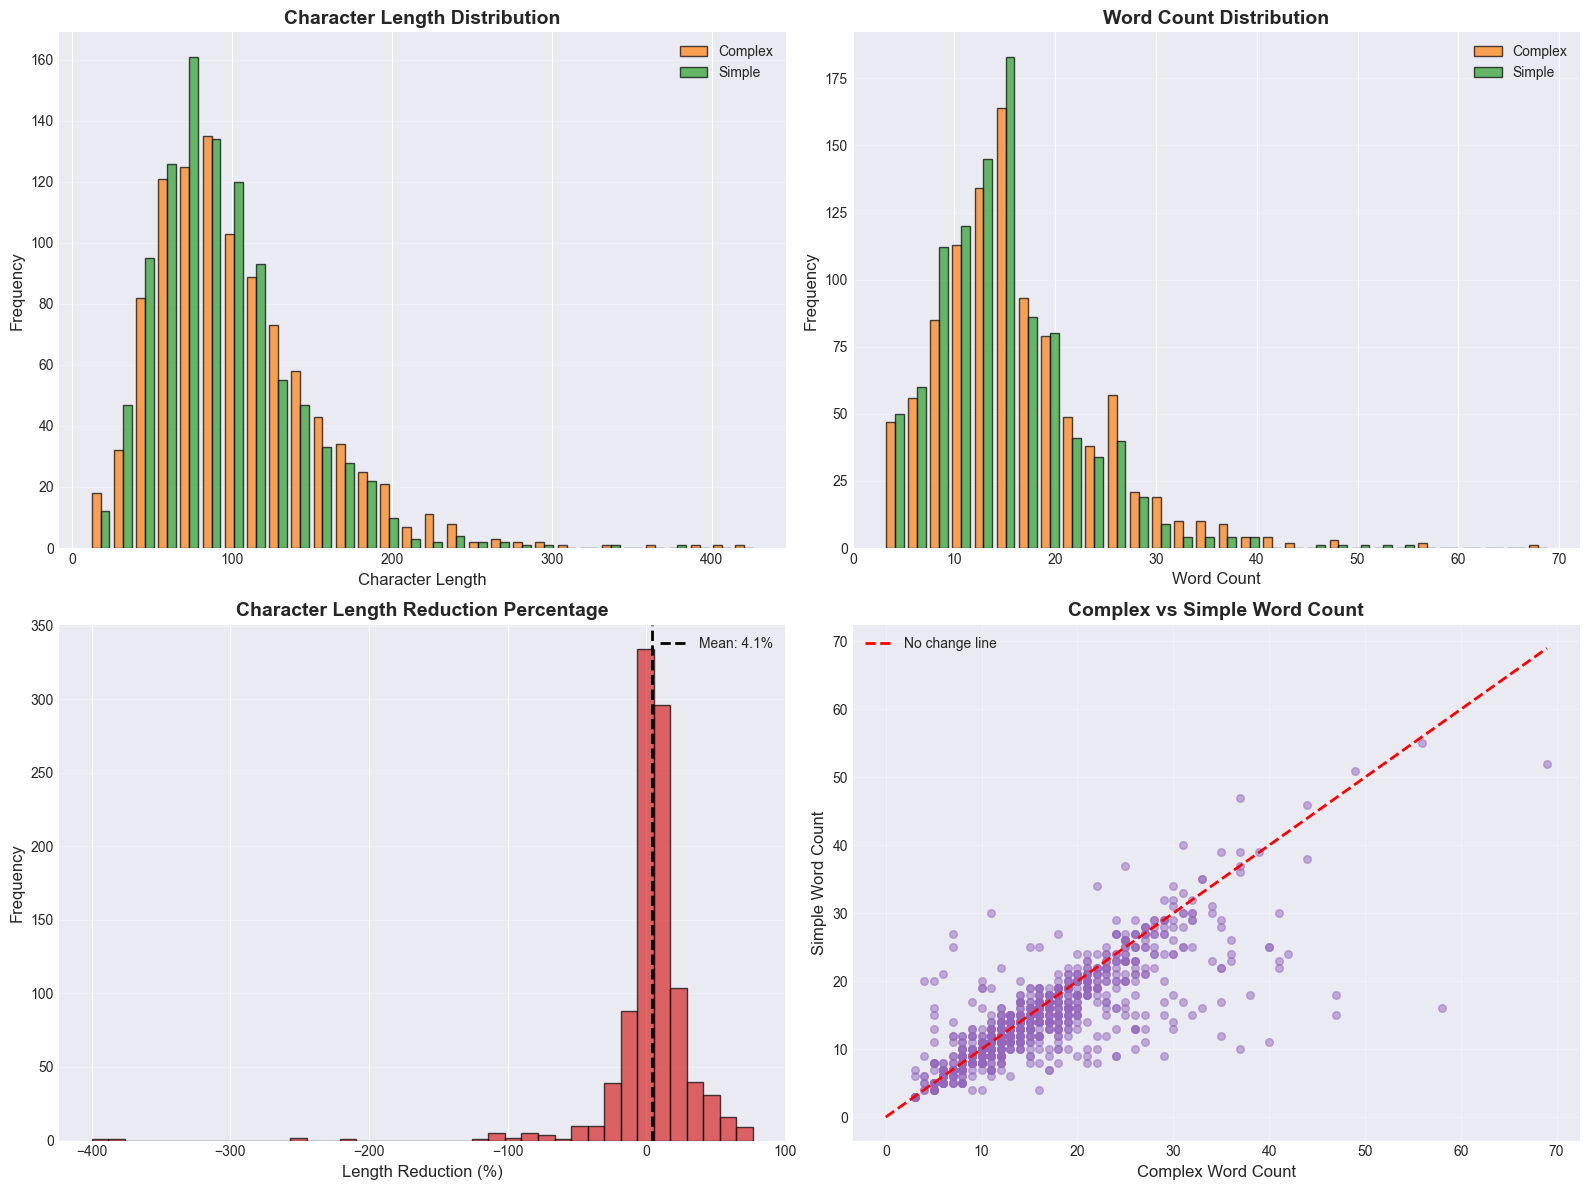

In [13]:
# Visualize length comparisons
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Character length comparison
axes[0, 0].hist([df['complex_length'], df['simple_length']], 
                bins=30, label=['Complex', 'Simple'], 
                color=['#ff7f0e', '#2ca02c'], alpha=0.7, edgecolor='black')
axes[0, 0].set_xlabel('Character Length', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Character Length Distribution', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# Word count comparison
axes[0, 1].hist([df['complex_words'], df['simple_words']], 
                bins=30, label=['Complex', 'Simple'], 
                color=['#ff7f0e', '#2ca02c'], alpha=0.7, edgecolor='black')
axes[0, 1].set_xlabel('Word Count', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Word Count Distribution', fontsize=14, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(axis='y', alpha=0.3)

# Length reduction percentage
axes[1, 0].hist(df['length_reduction_pct'], bins=40, color='#d62728', alpha=0.7, edgecolor='black')
axes[1, 0].axvline(df['length_reduction_pct'].mean(), color='black', linestyle='--', linewidth=2, label=f'Mean: {df["length_reduction_pct"].mean():.1f}%')
axes[1, 0].set_xlabel('Length Reduction (%)', fontsize=12)
axes[1, 0].set_ylabel('Frequency', fontsize=12)
axes[1, 0].set_title('Character Length Reduction Percentage', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(axis='y', alpha=0.3)

# Scatter plot: complex vs simple length
axes[1, 1].scatter(df['complex_words'], df['simple_words'], alpha=0.5, s=30, color='#9467bd')
axes[1, 1].plot([0, df['complex_words'].max()], [0, df['complex_words'].max()], 
                'r--', linewidth=2, label='No change line')
axes[1, 1].set_xlabel('Complex Word Count', fontsize=12)
axes[1, 1].set_ylabel('Simple Word Count', fontsize=12)
axes[1, 1].set_title('Complex vs Simple Word Count', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
print("Min/Max length_reduction_pct:", df['length_reduction_pct'].min(), df['length_reduction_pct'].max())

neg = df[df['length_reduction_pct'] < 0]
print(f"Negatief: {len(neg)} rows ({len(neg)/len(df)*100:.1f}%)")

cols = ['Document ID','Complex','Simple','complex_length','simple_length','length_reduction_pct','complex_words','simple_words']
print("\nMeest negatieve 20:")
display(neg.nsmallest(20, 'length_reduction_pct')[cols])

print("\nComplex zin erg kort (<20 tekens) en simple veel langer:")
short = neg[neg['complex_length'] < 20]
display(short.nsmallest(5, 'complex_length')[cols])

Min/Max length_reduction_pct: -400.0 76.92
Negatief: 283 rows (28.3%)

Meest negatieve 20:


,Document ID,Complex,Simple,complex_length,simple_length,length_reduction_pct,complex_words,simple_words
236,15,I-domein) is gemaakt in.,Vooral omdat er in het voorgenomen besluit een splitsing is gemaakt tussen de reorganisatie van ...,24,120,-400.00,4,20
754,22,Stemmen op 17 maart 2021,Dat is vooral voor kwetsbaardere kiezers die niet in de drukte van de verkiezingsdag op 17 maart...,24,115,-379.17,5,20
714,14,De organisatie van het Kwaku Summer Festival,In een apart traject werkten we met de organisatie van het Kwaku Summer festival aan voorstellen...,44,157,-256.82,7,25
904,34,Personen met een [land van herkomst] achtergrond,"Let op: als je het bijvoorbeeld hebt over ‘personen met een Surinaamse achtergrond’, dan gebruik...",48,167,-247.92,7,27
41,12,Wel zijn er globale plannen gemaakt.,Maar die gaan we de komende tijd maken en uiteraard bespreken we die met u. Wel zijn er globale ...,36,112,-211.11,6,21
521,14,Leerlingen van de basisscholen aan het park en de Kindercommissie Zuidoost,Met de (leerlingen van de) basisscholen langs het park was er een ontwerpmiddag over wat het par...,74,162,-118.92,11,30
107,33,Niet eens met besluit ?,Het kan dat u het niet eens bent met dit besluit.,23,49,-113.04,5,11
663,40,De Adviesraad naamgeving openbare ruimten,De naamgeving van openbare ruimten is vooral om plekken in de stad te kunnen aanduiden.,41,87,-112.20,5,15
430,38,(Voorbeeld: de groene stip of blauwe ruit van de Stadspas.,Met name voor onderwerpen of categorieën die vaak terugkomen (bijvoorbeeld: de groene stip of bl...,58,122,-110.34,10,19
152,14,Nieuwste versie plan Nelson Mandelapark,Al die wensen en zorgen gebruikten we om de nieuwste versie van het plan te maken.,39,82,-110.26,5,16



Complex zin erg kort (<20 tekens) en simple veel langer:


,Document ID,Complex,Simple,complex_length,simple_length,length_reduction_pct,complex_words,simple_words
848,14,Overleg met V&OR.,Dit moet in overleg met V&OR.,17,29,-70.59,3,6


## 4. Sentence Complexity Metrics

In [15]:
# Calculate average word length
df['complex_avg_word_len'] = df['complex_length'] / df['complex_words']
df['simple_avg_word_len'] = df['simple_length'] / df['simple_words']

# Count punctuation
df['complex_commas'] = df['Complex'].str.count(',')
df['simple_commas'] = df['Simple'].str.count(',')
df['complex_periods'] = df['Complex'].str.count(r'\.')
df['simple_periods'] = df['Simple'].str.count(r'\.')

print("Average Word Length:")
print(f"Complex: {df['complex_avg_word_len'].mean():.2f} characters")
print(f"Simple: {df['simple_avg_word_len'].mean():.2f} characters")
print(f"\nPunctuation Analysis:")
print(f"Average commas per sentence (Complex): {df['complex_commas'].mean():.2f}")
print(f"Average commas per sentence (Simple): {df['simple_commas'].mean():.2f}")
print(f"Average periods per sentence (Complex): {df['complex_periods'].mean():.2f}")
print(f"Average periods per sentence (Simple): {df['simple_periods'].mean():.2f}")

Average Word Length:
Complex: 6.48 characters
Simple: 6.42 characters

Punctuation Analysis:
Average commas per sentence (Complex): 0.34
Average commas per sentence (Simple): 0.22
Average periods per sentence (Complex): 0.90
Average periods per sentence (Simple): 1.08


## 5. Anonymization Pattern Analysis

In [16]:
# Count anonymization patterns
patterns = {
    '[NAME]': r'\[NAME\]',
    '[ORGANIZATION]': r'\[ORGANIZATION\]',
    '[ADDRESS]': r'\[ADDRESS\]',
    '[NUMBER]': r'\[NUMBER\]',
    'xxx xxx xxx': r'xxx xxx xxx'
}

anonymization_stats = {}
for pattern_name, pattern_regex in patterns.items():
    complex_count = df['Complex'].str.count(pattern_regex).sum()
    simple_count = df['Simple'].str.count(pattern_regex).sum()
    anonymization_stats[pattern_name] = {
        'Complex': complex_count,
        'Simple': simple_count,
        'Total': complex_count + simple_count
    }

anon_df = pd.DataFrame(anonymization_stats).T
print("Anonymization Pattern Occurrences:")
print(anon_df)
print(f"\nTotal anonymized entries: {anon_df['Total'].sum()}")

Anonymization Pattern Occurrences:
                Complex  Simple  Total
[NAME]                4       4      8
[ORGANIZATION]        6       6     12
[ADDRESS]             3       3      6
[NUMBER]              3       3      6
xxx xxx xxx           9       9     18

Total anonymized entries: 50


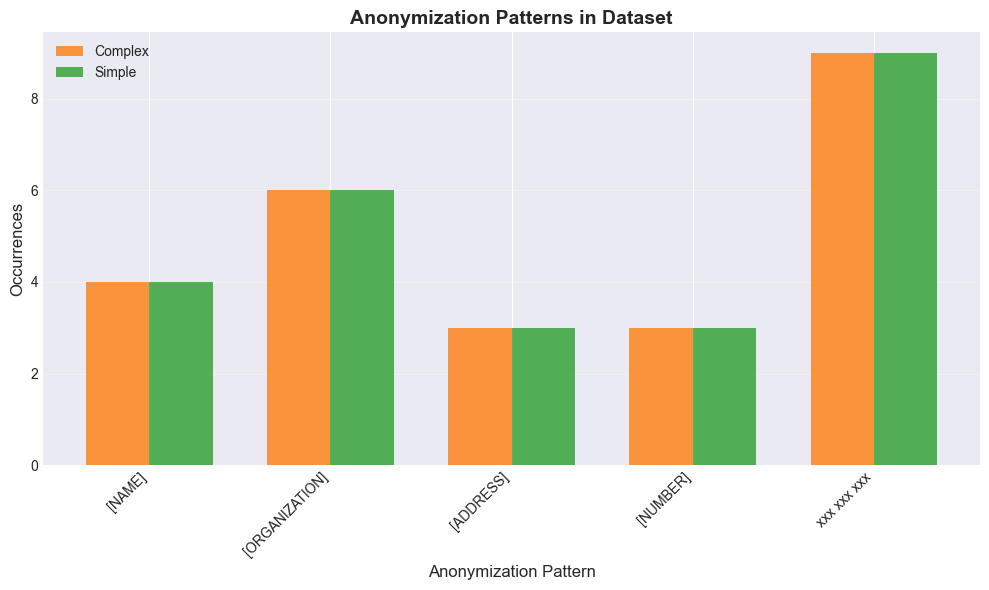

In [17]:
# Visualize anonymization patterns
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(anon_df))
width = 0.35

bars1 = ax.bar(x - width/2, anon_df['Complex'], width, label='Complex', color='#ff7f0e', alpha=0.8)
bars2 = ax.bar(x + width/2, anon_df['Simple'], width, label='Simple', color='#2ca02c', alpha=0.8)

ax.set_xlabel('Anonymization Pattern', fontsize=12)
ax.set_ylabel('Occurrences', fontsize=12)
ax.set_title('Anonymization Patterns in Dataset', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(anon_df.index, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Simplification Strategies Analysis

In [25]:
from sentence_transformers import SentenceTransformer
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Load pre-trained Dutch model
model = SentenceTransformer('sentence-transformers/distiluse-base-multilingual-cased-v2')

# Encode complex & simple sentences
print("Encoding sentences (this may take a minute)...")
complex_embeddings = model.encode(df['Complex'].tolist(), show_progress_bar=True)
simple_embeddings = model.encode(df['Simple'].tolist(), show_progress_bar=True)

# Calculate cosine similarity (0-1, where 1 = identical meaning)
df['semantic_similarity'] = [
    cosine_similarity([c], [s])[0][0] 
    for c, s in zip(complex_embeddings, simple_embeddings)
]

# Categorize based on semantic similarity
def categorize_simplification_semantic(row):
    sim = row['semantic_similarity']
    
    if sim >= 0.85:
        return 'Rephrasing (high semantic overlap)'
    elif sim >= 0.70:
        return 'Minor simplification (good meaning preservation)'
    elif sim >= 0.50:
        return 'Moderate simplification (partial meaning change)'
    else:
        return 'Substantial transformation (low semantic overlap)'

df['simplification_type'] = df.apply(categorize_simplification_semantic, axis=1)

print("\nSemantic Similarity Statistics:")
print(f"Mean similarity: {df['semantic_similarity'].mean():.3f}")
print(f"Std deviation: {df['semantic_similarity'].std():.3f}")
print(f"\nSimplification Type Distribution (Semantic-based):")
print(df['simplification_type'].value_counts())
print(f"\nPercentages:")
print(df['simplification_type'].value_counts(normalize=True) * 100)

modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

c:\Anaconda3\envs\maai2\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Freek Tindemans\.cache\huggingface\hub\models--sentence-transformers--distiluse-base-multilingual-cased-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/610 [00:00<?, ?B/s]

... (10 outputs left out)

Encoding sentences (this may take a minute)...


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]


Semantic Similarity Statistics:
Mean similarity: 0.882
Std deviation: 0.129

Simplification Type Distribution (Semantic-based):
simplification_type
Rephrasing (high semantic overlap)                   729
Minor simplification (good meaning preservation)     175
Moderate simplification (partial meaning change)      73
Substantial transformation (low semantic overlap)     23
Name: count, dtype: int64

Percentages:
simplification_type
Rephrasing (high semantic overlap)                   72.9
Minor simplification (good meaning preservation)     17.5
Moderate simplification (partial meaning change)      7.3
Substantial transformation (low semantic overlap)     2.3
Name: proportion, dtype: float64


AUTOMATISCHE BEPALING VAN AANTAL CATEGORIEËN EN THRESHOLDS

Descriptieve statistieken van semantic_similarity:
count    1000.000000
mean        0.882459
std         0.129302
min         0.175480
25%         0.840811
50%         0.926956
75%         0.973461
max         1.000000
Name: semantic_similarity, dtype: float64


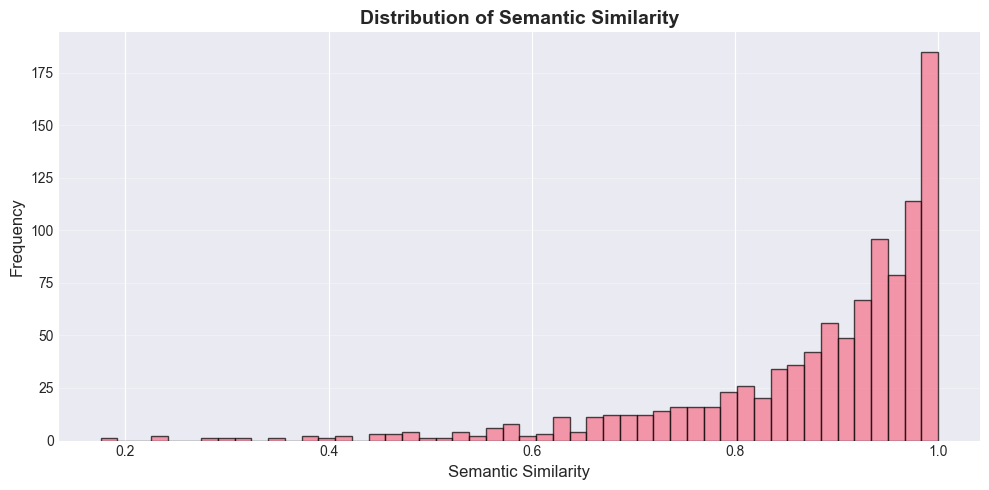


METHODE 1: K-Means + Silhouette Score (optimaal aantal clusters)
k=2: Silhouette Score = 0.698
k=3: Silhouette Score = 0.634
k=4: Silhouette Score = 0.610
k=5: Silhouette Score = 0.599
k=6: Silhouette Score = 0.575
k=7: Silhouette Score = 0.585

✓ Optimaal aantal clusters (hoogste Silhouette): k=2

Cluster centers: [0.6654514, 0.93469155]

METHODE 2: Jenks Natural Breaks Optimization
Jenks breakpoints (n=2): ['0.175', '0.798', '1.000']

METHODE 3: Gaussian Mixture Model (BIC voor model selectie)
k=2: BIC = -1852.4
k=3: BIC = -1967.1
k=4: BIC = -2085.4
k=5: BIC = -2074.5
k=6: BIC = -2072.6
k=7: BIC = -2061.1

✓ Optimaal aantal componenten (laagste BIC): k=4

VERGELIJKING VAN CLUSTERING METHODEN
             Methode  Optimaal k                                                 Voordeel
K-Means (Silhouette)           2                           Snelheid, duidelijke centroids
Jenks Natural Breaks           2 Geografisch bewezen, minimaliseert binnen-groep variance
           GMM (BIC)      

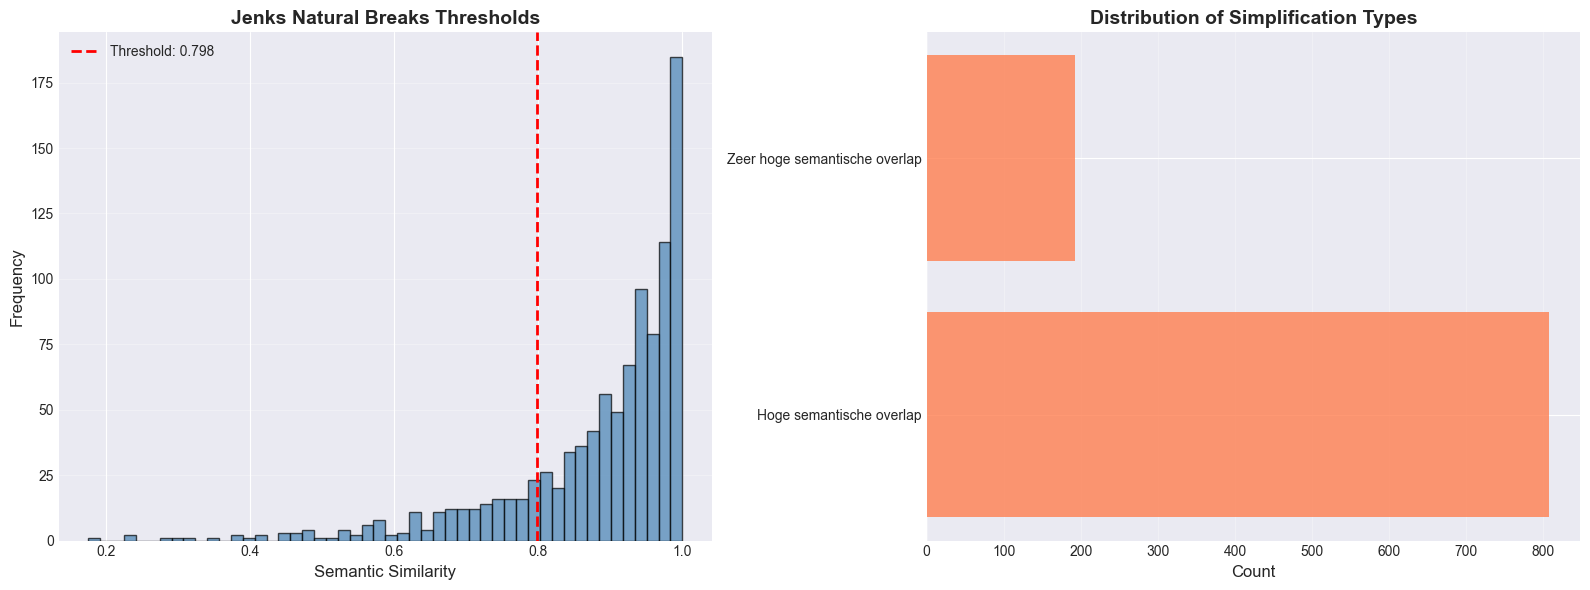

In [29]:
# Wetenschappelijk onderbouwde classificatie: automatische clustering
print("=" * 80)
print("AUTOMATISCHE BEPALING VAN AANTAL CATEGORIEËN EN THRESHOLDS")
print("=" * 80)

from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score, davies_bouldin_score
import jenkspy  # pip install jenkspy

# Analyseer de distributie
print(f"\nDescriptieve statistieken van semantic_similarity:")
print(df['semantic_similarity'].describe())

# Visualiseer distributie
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.hist(df['semantic_similarity'], bins=50, edgecolor='black', alpha=0.7)
ax.set_xlabel('Semantic Similarity', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Distribution of Semantic Similarity', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# === METHODE 1: Silhouette Score voor optimaal aantal clusters ===
print("\n" + "=" * 80)
print("METHODE 1: K-Means + Silhouette Score (optimaal aantal clusters)")
print("=" * 80)

X = df['semantic_similarity'].values.reshape(-1, 1)
silhouette_scores = []
k_range = range(2, 8)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print(f"k={k}: Silhouette Score = {score:.3f}")

# Best k
optimal_k = k_range[np.argmax(silhouette_scores)]
print(f"\n✓ Optimaal aantal clusters (hoogste Silhouette): k={optimal_k}")

# Fit final model
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_optimal.fit_predict(X)

# Bepaal thresholds uit cluster centers
cluster_centers = sorted(kmeans_optimal.cluster_centers_.flatten())
print(f"\nCluster centers: {cluster_centers}")

# === METHODE 2: Jenks Natural Breaks (geografisch geïnspireerd) ===
print("\n" + "=" * 80)
print("METHODE 2: Jenks Natural Breaks Optimization")
print("=" * 80)

# Jenks bepaalt optimale breakpoints die variance binnen groepen minimaliseert
n_classes = optimal_k  # Gebruik optimal_k van Silhouette
breaks_jenks = jenkspy.jenks_breaks(df['semantic_similarity'].values, n_classes=n_classes)
print(f"Jenks breakpoints (n={n_classes}): {[f'{b:.3f}' for b in breaks_jenks]}")

# Assign categories based on Jenks
def assign_jenks_category(sim, breaks):
    for i in range(len(breaks) - 1):
        if breaks[i] <= sim < breaks[i+1]:
            return i
    return len(breaks) - 2  # Last category

df['cluster_jenks'] = df['semantic_similarity'].apply(
    lambda x: assign_jenks_category(x, breaks_jenks)
)

# === METHODE 3: Gaussian Mixture Model (probabilistisch) ===
print("\n" + "=" * 80)
print("METHODE 3: Gaussian Mixture Model (BIC voor model selectie)")
print("=" * 80)

from sklearn.mixture import GaussianMixture

bic_scores = []
for k in k_range:
    gmm = GaussianMixture(n_components=k, random_state=42)
    gmm.fit(X)
    bic = gmm.bic(X)
    bic_scores.append(bic)
    print(f"k={k}: BIC = {bic:.1f}")

# Lower BIC = better
optimal_k_gmm = k_range[np.argmin(bic_scores)]
print(f"\n✓ Optimaal aantal componenten (laagste BIC): k={optimal_k_gmm}")

gmm_optimal = GaussianMixture(n_components=optimal_k_gmm, random_state=42)
df['cluster_gmm'] = gmm_optimal.fit_predict(X)

# === VERGELIJKING VAN METHODEN ===
print("\n" + "=" * 80)
print("VERGELIJKING VAN CLUSTERING METHODEN")
print("=" * 80)

comparison = pd.DataFrame({
    'Methode': ['K-Means (Silhouette)', 'Jenks Natural Breaks', 'GMM (BIC)'],
    'Optimaal k': [optimal_k, n_classes, optimal_k_gmm],
    'Voordeel': [
        'Snelheid, duidelijke centroids',
        'Geografisch bewezen, minimaliseert binnen-groep variance',
        'Probabilistisch, robuust voor overlappende clusters'
    ]
})
print(comparison.to_string(index=False))

# === KEUZE: JENKS (aanbevolen voor deze use-case) ===
print("\n" + "=" * 80)
print("GEKOZEN METHODE: Jenks Natural Breaks")
print("Reden: Minimaliseert variance binnen groepen, geografisch bewezen algoritme")
print("=" * 80)

# Map Jenks clusters to semantic categories
thresholds_jenks = breaks_jenks[1:-1]  # Remove min/max boundaries
print(f"\nThresholds: {[f'{t:.3f}' for t in thresholds_jenks]}")

# Dynamisch categorieën toewijzen
category_labels = [
    'Zeer hoge semantische overlap',
    'Hoge semantische overlap',
    'Matige semantische overlap',
    'Lage semantische overlap'
]

# Truncate or extend labels based on actual n_classes
category_labels = category_labels[:n_classes]

def categorize_jenks(cluster_id):
    return category_labels[cluster_id]

df['simplification_type'] = df['cluster_jenks'].apply(categorize_jenks)

print(f"\nFinale categorieën:")
for i, label in enumerate(category_labels):
    count = len(df[df['cluster_jenks'] == i])
    pct = count / len(df) * 100
    print(f"  {i+1}. {label}: {count} ({pct:.1f}%)")

# Tabel voor rapport
print("\n" + "=" * 80)
print("CLASSIFICATIETABEL VOOR RAPPORT")
print("=" * 80)

classification_table = pd.DataFrame({
    'Categorie': category_labels,
    'Semantische gelijkenis range': [
        f"{breaks_jenks[i]:.3f} – {breaks_jenks[i+1]:.3f}" 
        for i in range(len(category_labels))
    ],
    'Aantal': [len(df[df['cluster_jenks'] == i]) for i in range(len(category_labels))],
    'Percentage': [f"{len(df[df['cluster_jenks'] == i])/len(df)*100:.1f}%" for i in range(len(category_labels))]
})
print(classification_table.to_string(index=False))

# Visualisatie van de classificatie
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram met thresholds
axes[0].hist(df['semantic_similarity'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
for t in thresholds_jenks:
    axes[0].axvline(t, color='red', linestyle='--', linewidth=2, label=f'Threshold: {t:.3f}')
axes[0].set_xlabel('Semantic Similarity', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Jenks Natural Breaks Thresholds', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Bar chart van categorieën
category_counts = df['simplification_type'].value_counts()
axes[1].barh(range(len(category_counts)), category_counts.values, color='coral', alpha=0.8)
axes[1].set_yticks(range(len(category_counts)))
axes[1].set_yticklabels(category_counts.index)
axes[1].set_xlabel('Count', fontsize=12)
axes[1].set_title('Distribution of Simplification Types', fontsize=14, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


JACCARD SIMILARITY ANALYSE (Lexical Overlap)
Berekenen van Jaccard similarity...

Jaccard Similarity Statistics:
count    1000.000000
mean        0.646613
std         0.188670
min         0.083333
25%         0.500000
50%         0.654509
75%         0.800000
max         1.000000
Name: jaccard_similarity, dtype: float64

VERGELIJKING: Semantic vs Jaccard Similarity
             Metric     Mean      Std      Min  Max                                   Beschrijving
Semantic Similarity 0.882459 0.129302 0.175480  1.0 Semantische betekenisovereenkomst (embeddings)
 Jaccard Similarity 0.646613 0.188670 0.083333  1.0       Lexicale woordoverlap (set intersection)

Pearson correlatie tussen Semantic en Jaccard: 0.654


C:\Users\Freek Tindemans\AppData\Local\Temp\ipykernel_12824\1363124801.py:85: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Semantic', 'Jaccard'], patch_artist=True,


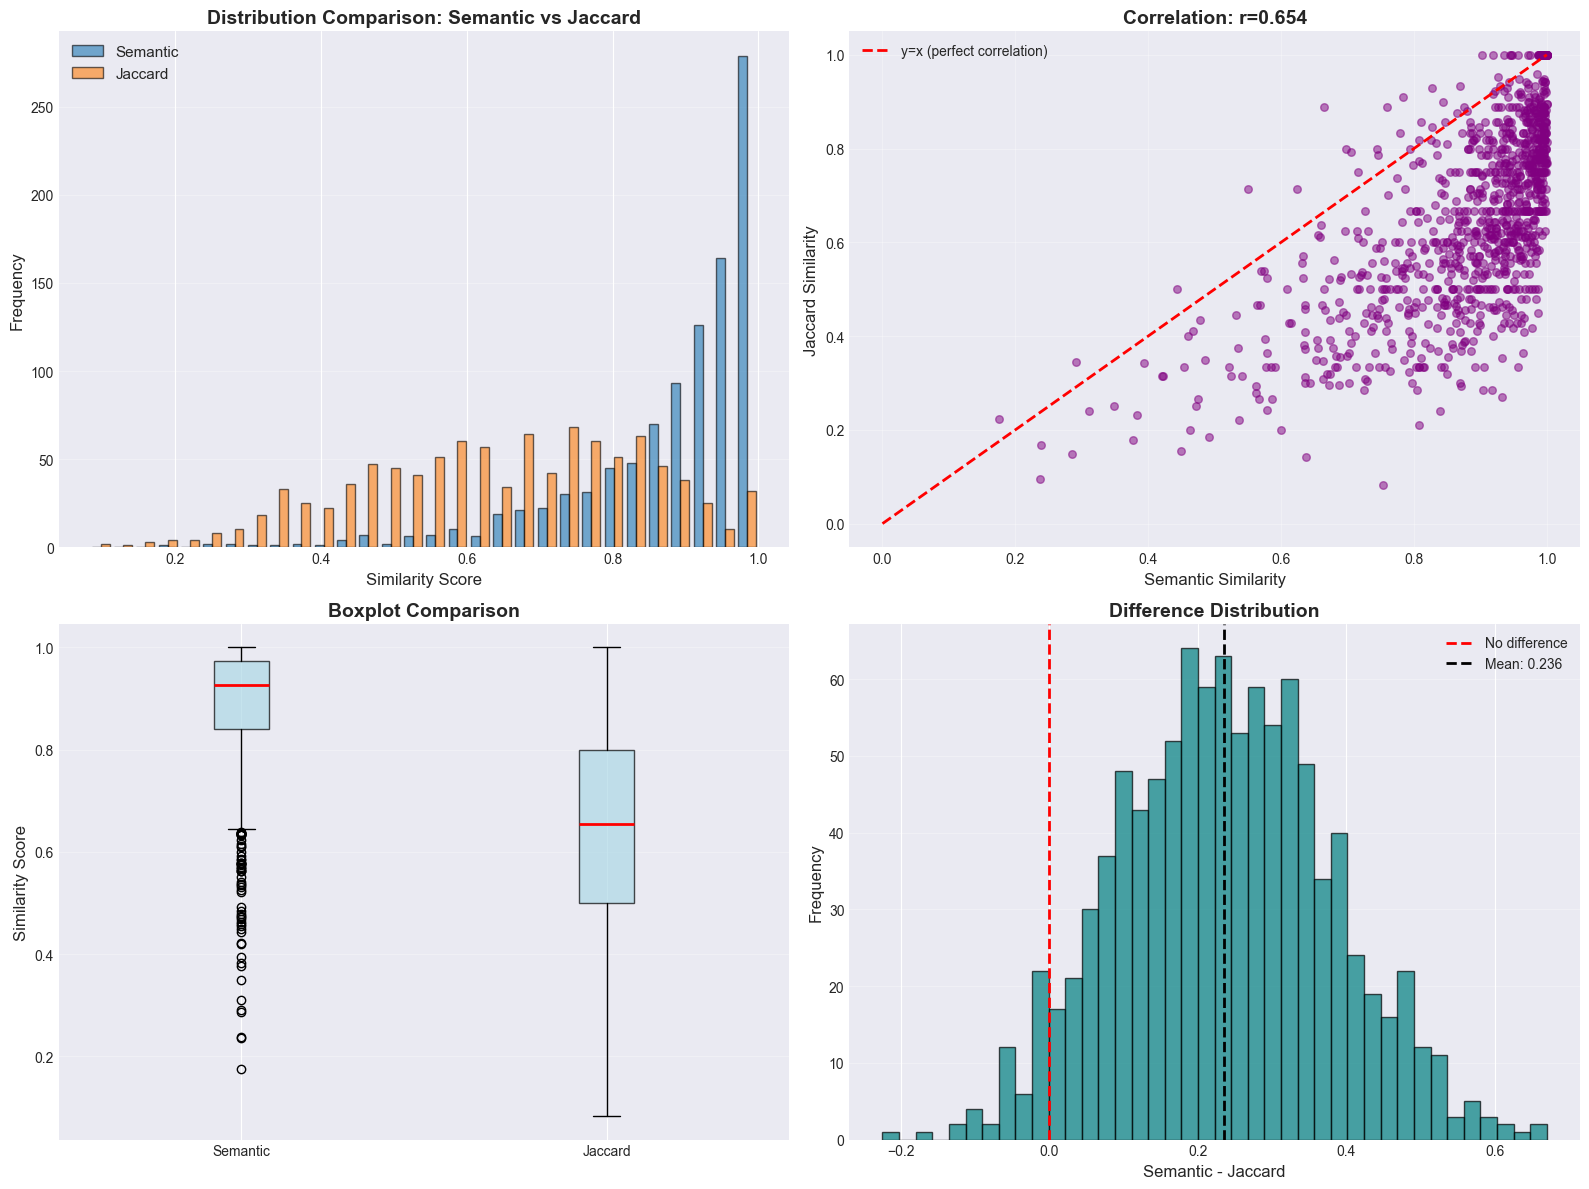


ANALYSE VAN EXTREME GEVALLEN

1. Hoge Semantic, Lage Jaccard (parafrase): 7 cases

Voorbeeld:
  Complex:  Er wordt doorlopend onderzoek gedaan.
  Simple:   Dit wordt doorlopend onderzocht.
  Semantic: 0.804
  Jaccard:  0.286

2. Lage Semantic, Hoge Jaccard (woorden hetzelfde, betekenis veranderd): 4 cases

Voorbeeld:
  Complex:  Zijn de opbouw en de opname van spaaruren ingeroosterd?
  Simple:   Als opbouw en opname van spaaruren ingeroosterd staan, gaat de opbouw gewoon door.
  Semantic: 0.570
  Jaccard:  0.538

3. Beide Hoog (minimale wijziging): 564 cases

Voorbeeld:
  Complex:  Beeld personen altijd af vanaf een normale kijkhoogte/perspectief.
  Simple:   Beeld personen altijd af vanaf een normale kijkhoogte en perspectief.
  Semantic: 0.957
  Jaccard:  0.636

4. Beide Laag (substantiële transformatie): 34 cases

Voorbeeld:
  Complex:  Wel zijn er globale plannen gemaakt.
  Simple:   Maar die gaan we de komende tijd maken en uiteraard bespreken we die met u. Wel zijn er globale pl

In [30]:
# === JACCARD SIMILARITY: Woordoverlap analyse ===
print("\n" + "=" * 80)
print("JACCARD SIMILARITY ANALYSE (Lexical Overlap)")
print("=" * 80)

from sklearn.metrics import jaccard_score

def calculate_jaccard(text1, text2):
    """
    Berekent Jaccard similarity op woord-niveau:
    Jaccard = |A ∩ B| / |A ∪ B|
    """
    # Tokenize en lowercase
    words1 = set(text1.lower().split())
    words2 = set(text2.lower().split())
    
    # Remove punctuation
    import string
    words1 = {w.strip(string.punctuation) for w in words1 if w.strip(string.punctuation)}
    words2 = {w.strip(string.punctuation) for w in words2 if w.strip(string.punctuation)}
    
    # Jaccard coefficient
    intersection = len(words1.intersection(words2))
    union = len(words1.union(words2))
    
    return intersection / union if union > 0 else 0.0

# Bereken Jaccard similarity voor alle pairs
print("Berekenen van Jaccard similarity...")
df['jaccard_similarity'] = df.apply(
    lambda row: calculate_jaccard(row['Complex'], row['Simple']),
    axis=1
)

print("\nJaccard Similarity Statistics:")
print(df['jaccard_similarity'].describe())

# Vergelijk met semantic similarity
print("\n" + "=" * 80)
print("VERGELIJKING: Semantic vs Jaccard Similarity")
print("=" * 80)

comparison_stats = pd.DataFrame({
    'Metric': ['Semantic Similarity', 'Jaccard Similarity'],
    'Mean': [df['semantic_similarity'].mean(), df['jaccard_similarity'].mean()],
    'Std': [df['semantic_similarity'].std(), df['jaccard_similarity'].std()],
    'Min': [df['semantic_similarity'].min(), df['jaccard_similarity'].min()],
    'Max': [df['semantic_similarity'].max(), df['jaccard_similarity'].max()],
    'Beschrijving': [
        'Semantische betekenisovereenkomst (embeddings)',
        'Lexicale woordoverlap (set intersection)'
    ]
})
print(comparison_stats.to_string(index=False))

# Correlatie tussen semantic en Jaccard
correlation = df['semantic_similarity'].corr(df['jaccard_similarity'])
print(f"\nPearson correlatie tussen Semantic en Jaccard: {correlation:.3f}")

# === VISUALISATIE ===
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Histogram vergelijking
axes[0, 0].hist([df['semantic_similarity'], df['jaccard_similarity']], 
                bins=30, label=['Semantic', 'Jaccard'], 
                color=['#1f77b4', '#ff7f0e'], alpha=0.6, edgecolor='black')
axes[0, 0].set_xlabel('Similarity Score', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Distribution Comparison: Semantic vs Jaccard', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Scatter plot: Semantic vs Jaccard
axes[0, 1].scatter(df['semantic_similarity'], df['jaccard_similarity'], 
                   alpha=0.5, s=30, color='purple')
axes[0, 1].plot([0, 1], [0, 1], 'r--', linewidth=2, label='y=x (perfect correlation)')
axes[0, 1].set_xlabel('Semantic Similarity', fontsize=12)
axes[0, 1].set_ylabel('Jaccard Similarity', fontsize=12)
axes[0, 1].set_title(f'Correlation: r={correlation:.3f}', fontsize=14, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Boxplot vergelijking
data_to_plot = [df['semantic_similarity'], df['jaccard_similarity']]
axes[1, 0].boxplot(data_to_plot, labels=['Semantic', 'Jaccard'], patch_artist=True,
                   boxprops=dict(facecolor='lightblue', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2))
axes[1, 0].set_ylabel('Similarity Score', fontsize=12)
axes[1, 0].set_title('Boxplot Comparison', fontsize=14, fontweight='bold')
axes[1, 0].grid(axis='y', alpha=0.3)

# 4. Heatmap: verschil tussen Semantic en Jaccard
df['similarity_difference'] = df['semantic_similarity'] - df['jaccard_similarity']
axes[1, 1].hist(df['similarity_difference'], bins=40, color='teal', alpha=0.7, edgecolor='black')
axes[1, 1].axvline(0, color='red', linestyle='--', linewidth=2, label='No difference')
axes[1, 1].axvline(df['similarity_difference'].mean(), color='black', linestyle='--', 
                   linewidth=2, label=f'Mean: {df["similarity_difference"].mean():.3f}')
axes[1, 1].set_xlabel('Semantic - Jaccard', fontsize=12)
axes[1, 1].set_ylabel('Frequency', fontsize=12)
axes[1, 1].set_title('Difference Distribution', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# === ANALYSE VAN EXTREME GEVALLEN ===
print("\n" + "=" * 80)
print("ANALYSE VAN EXTREME GEVALLEN")
print("=" * 80)

# Hoge semantic, lage Jaccard (parafrase zonder woordoverlap)
high_sem_low_jac = df[(df['semantic_similarity'] > 0.8) & (df['jaccard_similarity'] < 0.3)]
print(f"\n1. Hoge Semantic, Lage Jaccard (parafrase): {len(high_sem_low_jac)} cases")
if len(high_sem_low_jac) > 0:
    print("\nVoorbeeld:")
    example = high_sem_low_jac.iloc[0]
    print(f"  Complex:  {example['Complex']}")
    print(f"  Simple:   {example['Simple']}")
    print(f"  Semantic: {example['semantic_similarity']:.3f}")
    print(f"  Jaccard:  {example['jaccard_similarity']:.3f}")

# Lage semantic, hoge Jaccard (veel dezelfde woorden, andere betekenis)
low_sem_high_jac = df[(df['semantic_similarity'] < 0.6) & (df['jaccard_similarity'] > 0.5)]
print(f"\n2. Lage Semantic, Hoge Jaccard (woorden hetzelfde, betekenis veranderd): {len(low_sem_high_jac)} cases")
if len(low_sem_high_jac) > 0:
    print("\nVoorbeeld:")
    example = low_sem_high_jac.iloc[0]
    print(f"  Complex:  {example['Complex']}")
    print(f"  Simple:   {example['Simple']}")
    print(f"  Semantic: {example['semantic_similarity']:.3f}")
    print(f"  Jaccard:  {example['jaccard_similarity']:.3f}")

# Beide hoog (minimale wijziging)
both_high = df[(df['semantic_similarity'] > 0.8) & (df['jaccard_similarity'] > 0.6)]
print(f"\n3. Beide Hoog (minimale wijziging): {len(both_high)} cases")
if len(both_high) > 0:
    print("\nVoorbeeld:")
    example = both_high.iloc[0]
    print(f"  Complex:  {example['Complex']}")
    print(f"  Simple:   {example['Simple']}")
    print(f"  Semantic: {example['semantic_similarity']:.3f}")
    print(f"  Jaccard:  {example['jaccard_similarity']:.3f}")

# Beide laag (substantiële transformatie)
both_low = df[(df['semantic_similarity'] < 0.6) & (df['jaccard_similarity'] < 0.4)]
print(f"\n4. Beide Laag (substantiële transformatie): {len(both_low)} cases")
if len(both_low) > 0:
    print("\nVoorbeeld:")
    example = both_low.iloc[0]
    print(f"  Complex:  {example['Complex']}")
    print(f"  Simple:   {example['Simple']}")
    print(f"  Semantic: {example['semantic_similarity']:.3f}")
    print(f"  Jaccard:  {example['jaccard_similarity']:.3f}")

# === COMBINATIE-METRIC ===
print("\n" + "=" * 80)
print("GECOMBINEERDE METRIC: Weighted Average")
print("=" * 80)

# Gewogen gemiddelde (70% semantic, 30% Jaccard)
WEIGHT_SEMANTIC = 0.7
WEIGHT_JACCARD = 0.3

df['combined_similarity'] = (
    WEIGHT_SEMANTIC * df['semantic_similarity'] + 
    WEIGHT_JACCARD * df['jaccard_similarity']
)

print(f"\nGewogen gemiddelde ({WEIGHT_SEMANTIC*100:.0f}% Semantic, {WEIGHT_JACCARD*100:.0f}% Jaccard):")
print(df['combined_similarity'].describe())

# Tabel voor rapport
similarity_summary = pd.DataFrame({
    'Metric': ['Semantic', 'Jaccard', 'Combined (0.7 + 0.3)'],
    'Mean': [
        df['semantic_similarity'].mean(),
        df['jaccard_similarity'].mean(),
        df['combined_similarity'].mean()
    ],
    'Std': [
        df['semantic_similarity'].std(),
        df['jaccard_similarity'].std(),
        df['combined_similarity'].std()
    ],
    'Beschrijving': [
        'Betekenisovereenkomst (embeddings)',
        'Woordoverlap (set intersection)',
        'Gecombineerde metric'
    ]
})
print("\n" + similarity_summary.to_string(index=False))

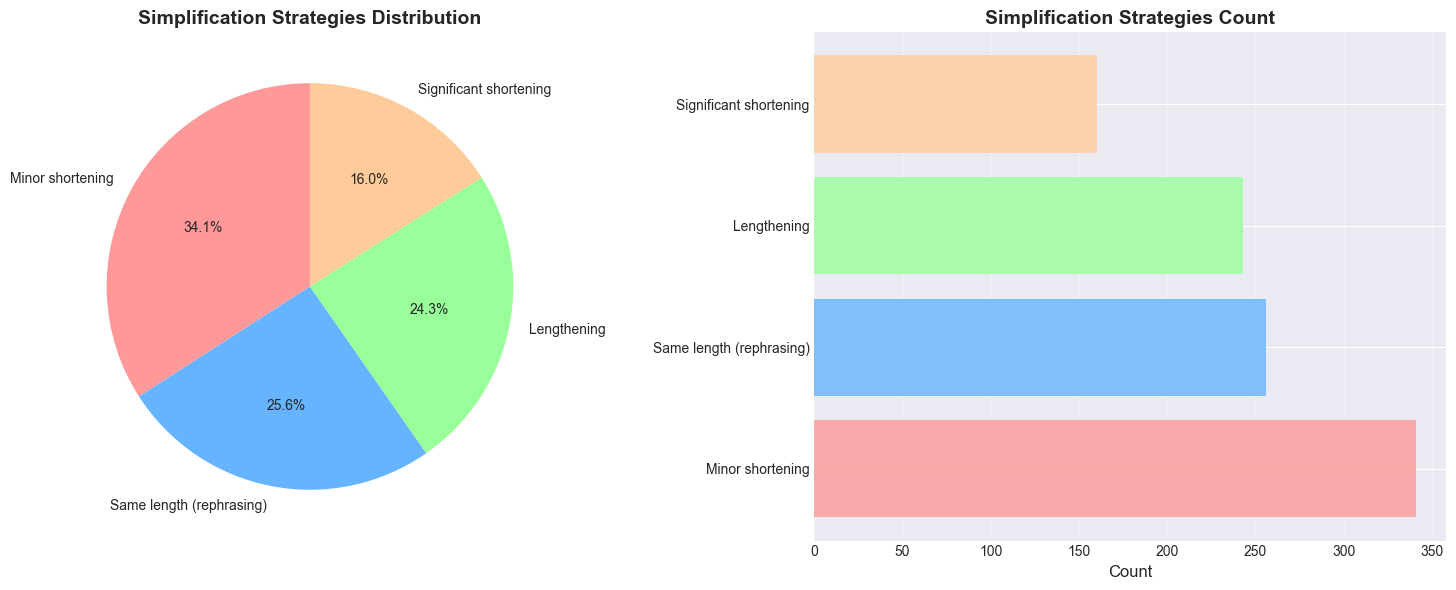

In [20]:
# Visualize simplification strategies
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pie chart
simplification_counts = df['simplification_type'].value_counts()
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
axes[0].pie(simplification_counts.values, labels=simplification_counts.index, 
            autopct='%1.1f%%', startangle=90, colors=colors)
axes[0].set_title('Simplification Strategies Distribution', fontsize=14, fontweight='bold')

# Bar chart
axes[1].barh(simplification_counts.index, simplification_counts.values, color=colors, alpha=0.8)
axes[1].set_xlabel('Count', fontsize=12)
axes[1].set_title('Simplification Strategies Count', fontsize=14, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Common Word Analysis

In [21]:
# Analyze common words in complex vs simple
def get_word_frequency(series, top_n=20):
    all_words = ' '.join(series.str.lower()).split()
    # Remove punctuation
    all_words = [re.sub(r'[^\w\s]', '', word) for word in all_words]
    all_words = [word for word in all_words if word]  # Remove empty strings
    return Counter(all_words).most_common(top_n)

complex_words_freq = get_word_frequency(df['Complex'], 30)
simple_words_freq = get_word_frequency(df['Simple'], 30)

print("Top 20 words in Complex sentences:")
for word, count in complex_words_freq[:20]:
    print(f"  {word}: {count}")

print("\nTop 20 words in Simple sentences:")
for word, count in simple_words_freq[:20]:
    print(f"  {word}: {count}")

Top 20 words in Complex sentences:
  de: 1155
  van: 565
  het: 471
  een: 442
  en: 435
  in: 341
  is: 254
  op: 224
  voor: 203
  met: 200
  te: 198
  dat: 146
  u: 142
  om: 130
  of: 124
  je: 124
  aan: 120
  als: 113
  worden: 110
  dit: 103

Top 20 words in Simple sentences:
  de: 1034
  het: 446
  van: 433
  een: 410
  en: 390
  in: 277
  voor: 236
  op: 185
  is: 181
  met: 179
  we: 176
  u: 163
  dat: 157
  te: 150
  of: 136
  om: 128
  je: 106
  aan: 105
  dit: 97
  als: 96


## 8. Examples of Different Simplification Types

In [22]:
# Show examples of each simplification type
print("=" * 100)
print("EXAMPLES OF SIMPLIFICATION STRATEGIES")
print("=" * 100)

for simp_type in df['simplification_type'].unique():
    print(f"\n{simp_type.upper()}:")
    print("-" * 100)
    examples = df[df['simplification_type'] == simp_type].head(3)
    for idx, row in examples.iterrows():
        print(f"\nDocument {row['Document ID']}:")
        print(f"  Complex:  {row['Complex']}")
        print(f"  Simple:   {row['Simple']}")
        print(f"  Words: {row['complex_words']} → {row['simple_words']} (reduction: {row['word_reduction']})")
    print("-" * 100)

EXAMPLES OF SIMPLIFICATION STRATEGIES

MINOR SHORTENING:
----------------------------------------------------------------------------------------------------

Document 39:
  Complex:  Zijn jouw trainers juist wel op zoek naar verdieping?
  Simple:   Misschien zoeken uw trainers juist wel meer verdieping.
  Words: 9 → 8 (reduction: 1)

Document 27:
  Complex:  Uw bewoner kan vooraf de gezondheidscheck doen als hij/zij gaat stemmen in een stemlokaal.
  Simple:   Uw bewoners kunnen voor het stemmen de gezondheidscheck doen in een stemlokaal.
  Words: 14 → 12 (reduction: 2)

Document 15:
  Complex:  De resultaten en beoogde verbeteringen worden ook met de ondernemingsraad besproken.
  Simple:   De resultaten en gewenste verbeteringen worden ook met ons besproken.
  Words: 11 → 10 (reduction: 1)
----------------------------------------------------------------------------------------------------

LENGTHENING:
-----------------------------------------------------------------------------------

## 9. Summary Statistics

In [23]:
# Create comprehensive summary
summary = {
    'Dataset Overview': {
        'Total sentence pairs': len(df),
        'Unique documents': df['Document ID'].nunique(),
        'Avg pairs per document': f"{doc_counts.mean():.2f}"
    },
    'Length Metrics': {
        'Avg complex length (chars)': f"{df['complex_length'].mean():.2f}",
        'Avg simple length (chars)': f"{df['simple_length'].mean():.2f}",
        'Avg length reduction (chars)': f"{df['length_reduction'].mean():.2f}",
        'Avg length reduction (%)': f"{df['length_reduction_pct'].mean():.2f}%"
    },
    'Word Metrics': {
        'Avg complex words': f"{df['complex_words'].mean():.2f}",
        'Avg simple words': f"{df['simple_words'].mean():.2f}",
        'Avg word reduction': f"{df['word_reduction'].mean():.2f}",
        'Avg word reduction (%)': f"{df['word_reduction_pct'].mean():.2f}%"
    },
    'Complexity Metrics': {
        'Avg word length complex': f"{df['complex_avg_word_len'].mean():.2f} chars",
        'Avg word length simple': f"{df['simple_avg_word_len'].mean():.2f} chars",
        'Avg commas complex': f"{df['complex_commas'].mean():.2f}",
        'Avg commas simple': f"{df['simple_commas'].mean():.2f}"
    },
    'Anonymization': {
        'Total anonymized entries': int(anon_df['Total'].sum()),
        'Names': int(anon_df.loc['[NAME]', 'Total']),
        'Organizations': int(anon_df.loc['[ORGANIZATION]', 'Total']),
        'Addresses': int(anon_df.loc['[ADDRESS]', 'Total']),
        'Phone numbers': int(anon_df.loc['[NUMBER]', 'Total'])
    }
}

print("\n" + "=" * 80)
print("DATASET SUMMARY")
print("=" * 80)
for category, metrics in summary.items():
    print(f"\n{category}:")
    for metric, value in metrics.items():
        print(f"  {metric}: {value}")
print("=" * 80)


DATASET SUMMARY

Dataset Overview:
  Total sentence pairs: 1000
  Unique documents: 47
  Avg pairs per document: 21.28

Length Metrics:
  Avg complex length (chars): 103.60
  Avg simple length (chars): 93.99
  Avg length reduction (chars): 9.61
  Avg length reduction (%): 4.14%

Word Metrics:
  Avg complex words: 16.09
  Avg simple words: 14.78
  Avg word reduction: 1.31
  Avg word reduction (%): 2.76%

Complexity Metrics:
  Avg word length complex: 6.48 chars
  Avg word length simple: 6.42 chars
  Avg commas complex: 0.34
  Avg commas simple: 0.22

Anonymization:
  Total anonymized entries: 50
  Names: 8
  Organizations: 12
  Addresses: 6
  Phone numbers: 6


## 10. Export Enhanced Dataset

In [24]:
# Save enhanced dataset with all calculated metrics
output_columns = [
    'Document ID', 'Complex', 'Simple',
    'complex_length', 'simple_length', 'length_reduction', 'length_reduction_pct',
    'complex_words', 'simple_words', 'word_reduction', 'word_reduction_pct',
    'complex_avg_word_len', 'simple_avg_word_len',
    'complex_commas', 'simple_commas',
    'simplification_type'
]

df[output_columns].to_csv('complex-simple-v1-analyzed.csv', index=False)
print("Enhanced dataset saved to: complex-simple-v1-analyzed.csv")

Enhanced dataset saved to: complex-simple-v1-analyzed.csv
